<a href="https://colab.research.google.com/github/Boniphace-pixels/Docker_compose/blob/main/Copy_of_Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

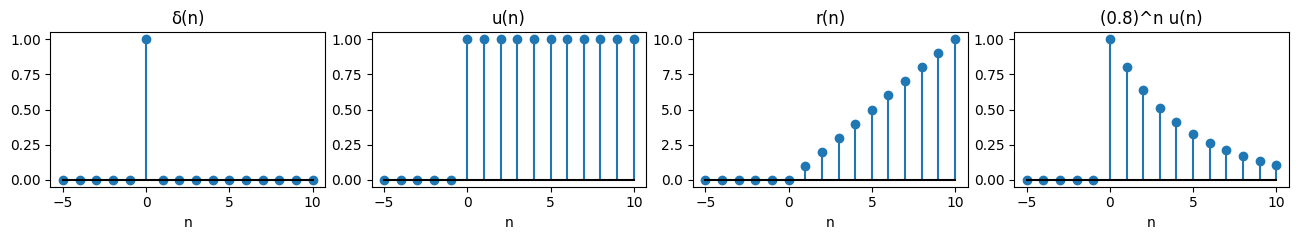

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step = (n >= 0).astype(float)    # unit step
ramp = n * step                  # unit ramp
expo = 0.8**n * step             # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.5))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()
# Expected result for Task 1.1 (handout Figure 1.4)

fs = 16000 Hz, duration = 2.00 s


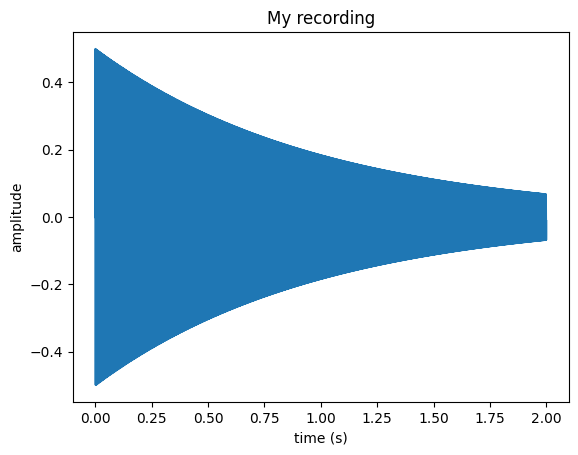

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fname = "my_voice.wav"  # change to your file
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:  # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))  # normalise to [-1, 1]
    t = np.arange(len(x)) / fs
else:  # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

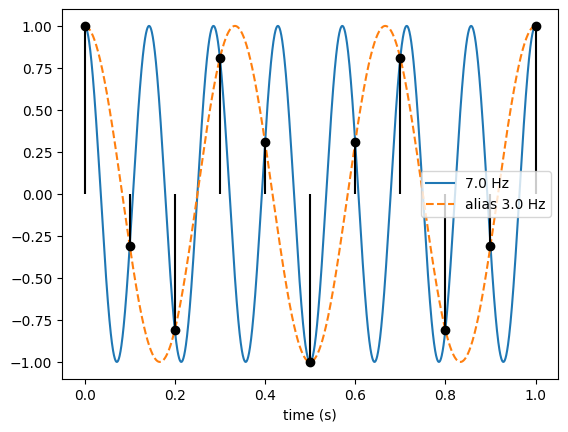

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)  # dense grid = "analog"
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs*round(f0/fs))

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"alias {f_alias} Hz")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", basefmt=" ")
plt.xlabel("time (s)"); plt.legend(); plt.show()

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio

fname = "my_voice.wav"  # your Week 1 recording
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    # 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

for k in [2, 4, 8]:
    naive = x[::k]  # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")  # low-pass, then drop samples
    print("fs ->", fs // k, "Hz")
    display(Audio(naive, rate=fs//k))
    display(Audio(proper, rate=fs//k))

fs -> 22050 Hz


fs -> 11025 Hz


fs -> 5512 Hz


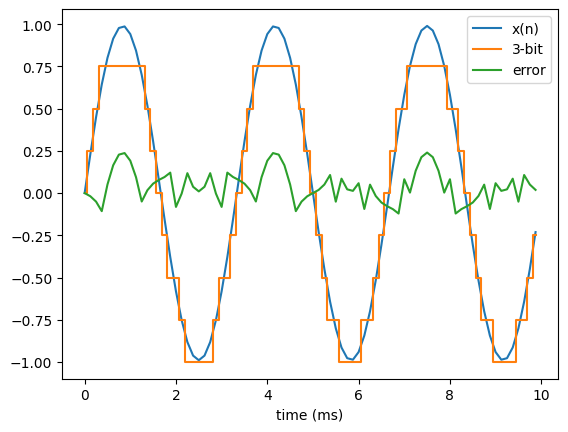

In [ ]:
def quantize(x, bits, full_scale=1.0):
 delta = 2*full_scale / 2**bits
 q = np.round(x/delta)*delta
 return np.clip(q, -full_scale, full_scale - delta)
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()

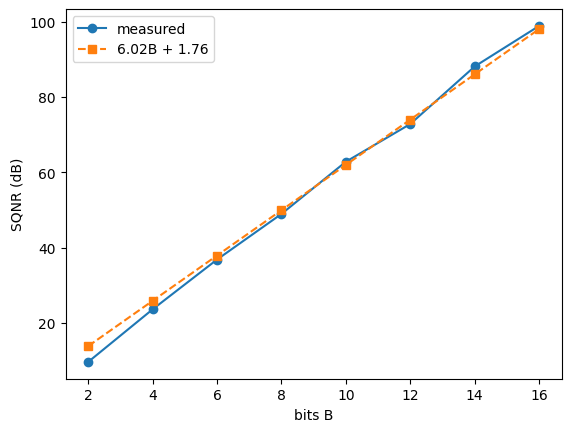

In [ ]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.show()

In [ ]:
import numpy as np

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))  # expected [1. 3. 6. 6. 4. 1.]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]


In [ ]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
 "n x(n)": lambda x: np.arange(len(x)) * x,
 "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
 linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
 xd = np.concatenate([np.zeros(5), x1])[:50] # delay input by 5
 yd = np.concatenate([np.zeros(5), T(x1)])[:50] # delay output by 5
 tinv = np.allclose(T(xd), yd)
 print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


estimated delay: 37 samples


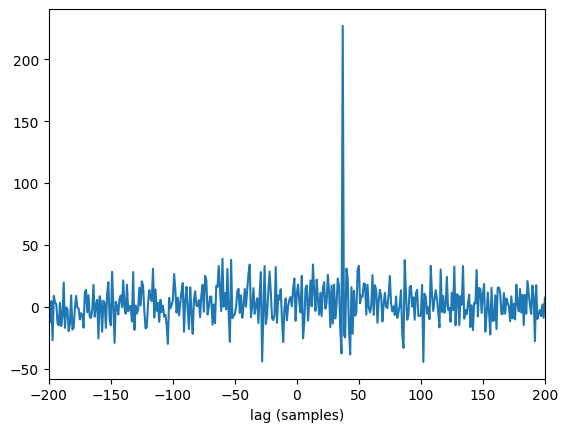

In [ ]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500) # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
print("estimated delay:", lags[np.argmax(r)], "samples")
plt.plot(lags, r); plt.xlim(-200, 200); plt.xlabel("lag (samples)"); plt.show()

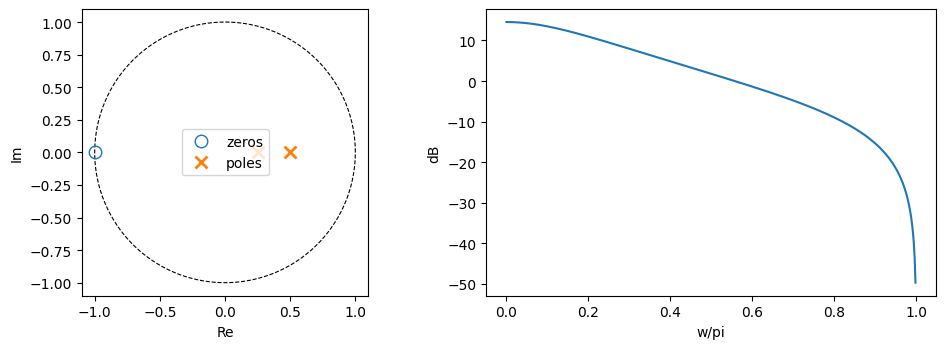

poles: [0.5  0.25]  stable: True


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H))); ax2.set_xlabel("w/pi")
ax2.set_ylabel("dB")
plt.tight_layout(); plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

In [ ]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print(np.allclose(x_pf, x_lf))

residues [-1.  2.] poles [0.25 0.5 ]
True
